# Шапка

ML-HW09-v1 TEAM-11. AI-Agents исследование

- Руденко Евгений Александрович
- Сажин Семён Михайлович
- Тихомиров Алексей Константинович

## Стэнфордский курс CS 329a «Самосовершенствующиеся ИИ-агенты». Домашнее задание № 1

В этом домашнем задании мы рассмотрим основные методы масштабирования вычислений на этапе формирования ответа и самосовершенствования моделей.

Домашнее задание состоит из 5 частей:

1. Оценка без примеров (zero-shot) — 10 баллов
2. Голосование большинством — 30 баллов
3. Выбор лучшего из N ответов с помощью генеративной модели вознаграждения — 30 баллов
4. Самосовершенствование с использованием обратной связи — 45 баллов
5. Анализ результатов — 15 баллов




### Условия проведения

Для всех методов используется Grok 4.7 через Cursor в режиме Low Fast (reasoning effort: low, fast: true). Сохраняются 30 задач AIME25, два раздельных пула по 16 ответов, уровни голосования 1/2/4/8/16 и три этапа самосовершенствования. Инструменты агента отключены, токенный лимит не задан. Температура в этом интерфейсе не управляется; числа 0.7, 0.3 и 0 в исходном коде не означают, что Cursor их применил.

Сравнение вычислительных затрат в выводах относится к внешним запускам агента: 1 для базового ответа, N для голосования, N+1 для LLM-отбора и 3 для самосовершенствования. Число внутренних вызовов модели и их стоимость неизвестны; равенство стоимости разных запусков не предполагается. Веса модели не обучаются.

Системная инструкция задания передаётся в составе пользовательского запроса; встроенные инструкции Cursor сохраняются. Каждый ответ создаётся в новой пустой сессии, однако статистическая независимость генераций этим интерфейсом не подтверждается.

Указанные бюджеты относятся к успешным получениям ответов; неудачные попытки в них не учтены. Всего сохранено 1110 успешных внешних запусков.


In [1]:
%pip install --editable "git+https://github.com/stanford-cs329a/cs329a-homework1-fall2025-public.git#egg=cs329_hw1" --config-settings editable_mode=compat
%pip install cursor-sdk==1.0.38


Obtaining cs329_hw1 from git+https://github.com/stanford-cs329a/cs329a-homework1-fall2025-public.git#egg=cs329_hw1
  Updating d:\git repositories\mo2\mo3_team_colabs\.venv\src\cs329-hw1 clone
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for cs329_hw1 (pyproject.toml): started
  Building editable for cs329_hw1 (pyproject.toml): finished with status 'done'
  Created wheel for cs329_hw1: filename=cs329_hw1-0.1.0-0.editable-py3-none-any.whl size=3900 sha256=b504c8c590fb4f30e2ef2517332b58d90ae58cafc8c90ed44afd17c48e5da154
  Stor

  Running command git fetch -q --tags
  Running command git reset --hard -q 6f6eb053aab7b0a77d7b5947703feea5b56b5fca

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: D:\Git Repositories\MO2\mo3_team_colabs\.venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: D:\Git Repositories\MO2\mo3_team_colabs\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import json
import os
import site
import subprocess
import sysconfig
from contextlib import contextmanager
from concurrent.futures import ThreadPoolExecutor, as_completed
from time import sleep
from queue import Queue, Empty
from threading import Thread
from dataclasses import asdict
from tempfile import TemporaryDirectory
from collections import Counter
from hashlib import sha256
from pathlib import Path
from multiprocessing import Pool, TimeoutError as VerificationTimeoutError
from typing import List, Union

import matplotlib.pyplot as plt
from cursor_sdk import Agent, AgentOptions, LocalAgentOptions, ModelSelection, ModelParameterValue, Cursor, CursorClient, CursorAgentError, InternalServerError
from cursor_sdk._bridge import resolve_bridge_path, parse_discovery_line, BridgeEndpoint
from dotenv import load_dotenv
from tenacity import retry, retry_if_exception, stop_after_attempt, wait_random_exponential
from tqdm import tqdm

# Подключаем установленный пакет без перезапуска ядра и потери переменных.
site.addsitedir(sysconfig.get_path("purelib"))

from cs329_hw1.inference.litellm_models import LiteLLMModel
from cs329_hw1.methods import get_verifier
from cs329_hw1.methods.simple_samplers import SampleMultiple as BaseSampleMultiple
from cs329_hw1.tasks import AIME25
from cs329_hw1.tasks.math_utils import extract_answer, strip_string, math_equal

load_dotenv()

HF_TOKEN = os.getenv("HUGGINGFACE_HUB_TOKEN")
DEBUG_MODE = False

PROBLEM_LIMIT = 30
N_CANDIDATES = 16
EXPERIMENT_ID = "aime25-full30-n16-cursor-low-fast-v1"
MODEL_PARAMETERS = {"context": "256k", "reasoning_effort": "low", "fast": "true"}
RUN_DEMONSTRATIONS = False

# Каталог не генерирует ответы; после выбора модели этот флаг можно отключить.
LIST_CURSOR_MODELS = False


### Набор данных AIME25
Мы будем работать с набором данных AIME25 с платформы [Hugging Face](https://huggingface.co/datasets/math-ai/aime25).
Этот набор содержит 30 сложных математических задач Американского пригласительного математического экзамена (AIME).
Эти задачи значительно сложнее обычных школьных задач по математике и требуют продвинутых методов решения.
<br>
Сначала познакомимся с набором данных.


In [3]:
aime25 = AIME25(hf_token=HF_TOKEN)
all_problems = aime25.get_problems(debug_mode=DEBUG_MODE)
problems = all_problems[:PROBLEM_LIMIT]
system_prompt = aime25.get_system_prompt()

# Каждая задача представлена словарём с ключами "problem", "answer" и "id"
print(f"Loaded {len(problems)} AIME25 problems")
print("Problem: ", problems[0]["problem"])
print("answer: ", problems[0]["answer"])

Using the latest cached version of the dataset since math-ai/aime25 couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at C:\Users\tikho\.cache\huggingface\datasets\math-ai___aime25\default\0.0.0\563bb8404243c5f09de6ec262f2db674fe5bce9b (last modified on Sat Oct 17 16:19:18 2026).


Loaded 30 AIME25 problems
Problem:  Suppose $\triangle ABC$ has angles $\angle BAC = 84^\circ, \angle ABC=60^\circ,$ and $\angle ACB = 36^\circ.$ Let $D, E,$ and $F$ be the midpoints of sides $\overline{BC}, \overline{AC},$ and $\overline{AB},$ respectively. The circumcircle of $	riangle DEF$ intersects $\overline{BD}, \overline{AE},$ and $\overline{AF}$ at points $G, H,$ and $J,$ respectively. The points $G, D, E, H, J,$ and $F$ divide the circumcircle of $\triangle DEF$ into six minor arcs, as shown. Find $\overarc{DE}+2\cdot \overarc{HJ} + 3\cdot \overarc{FG},$ where the arcs are measured in degrees.[asy] import olympiad; size(6cm); defaultpen(fontsize(10pt)); pair B = (0, 0), A = (Cos(60), Sin(60)), C = (Cos(60)+Sin(60)/Tan(36), 0), D = midpoint(B--C), E = midpoint(A--C), F = midpoint(A--B); guide circ = circumcircle(D, E, F); pair G = intersectionpoint(B--D, circ), J = intersectionpoints(A--F, circ)[0], H = intersectionpoints(A--E, circ)[0]; draw(B--A--C--cycle); draw(D--E--F--cyc

Здесь каждая задача представлена словарём с ключами `"problem"` и `"answer"`.
<br>
Значение `"problem"` содержит условие математической задачи, а `"answer"` — правильный ответ. Важно, что это не тест с вариантами ответа, поэтому ответ часто может представлять собой математическое выражение.



### Полезные инструменты
Чтобы помочь вам реализовать методы, рассматриваемые в этом домашнем задании, мы подготовили несколько полезных функций в модуле `cs329_hw1.methods`. Рекомендуем ознакомиться с этой функцией, а также с другими функциями, которые будут представлены далее: это поможет понять их возможности и способы применения при выполнении задания.


In [4]:
MODEL_NAME = os.getenv("CURSOR_MODEL", "").strip()


class ResponseStore:
    """Сохраняет каждый готовый ответ и продолжает прерванный расчёт."""

    def __init__(self, directory):
        self.directory = Path(directory)
        self.directory.mkdir(parents=True, exist_ok=True)

    def _path(self, request):
        encoded = json.dumps(request, ensure_ascii=False, sort_keys=True).encode("utf-8")
        return self.directory / f"{sha256(encoded).hexdigest()}.json"

    def load(self, request):
        path = self._path(request)
        if not path.exists():
            return None
        record = json.loads(path.read_text(encoding="utf-8"))
        answer = record.get("answer")
        if (record.get("request") != request or not isinstance(answer, str)
                or not answer.strip()
                or record.get("answer_sha256") != sha256(answer.encode("utf-8")).hexdigest()):
            raise ValueError("Сохранённый ответ повреждён или относится к другому запросу.")
        return record

    @staticmethod
    def write_json(path, data):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + ".tmp")
        with temporary.open("w", encoding="utf-8") as file:
            json.dump(data, file, ensure_ascii=False, indent=2)
            file.flush()
            os.fsync(file.fileno())
        os.replace(temporary, path)

    def save(self, request, answer, metadata):
        record = {
            "request": request,
            "answer": answer,
            "answer_sha256": sha256(answer.encode("utf-8")).hexdigest(),
            **metadata,
        }
        self.write_json(self._path(request), record)

    def records(self):
        return [json.loads(path.read_text(encoding="utf-8"))
                for path in sorted(self.directory.glob("*.json"))]


notebook_file = globals().get("__vsc_ipynb_file__")
checkpoint_root = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
CHECKPOINT_DIR = checkpoint_root / ".practice03_checkpoints" / EXPERIMENT_ID
response_store = ResponseStore(CHECKPOINT_DIR / "responses")

@contextmanager
def open_cursor_client(workspace):
    """Читает discovery через поток: Windows select не поддерживает каналы процесса."""
    process = subprocess.Popen(
        [resolve_bridge_path(), "--workspace", str(workspace),
         "--state-root", str(Path(workspace) / ".state"),
         "--local-store", json.dumps({"type": "sqlite", "rootDir": str(Path(workspace) / "s")}),
         "--host", "127.0.0.1", "--max-concurrent-agents", "1"],
        stdout=subprocess.DEVNULL, stderr=subprocess.PIPE,
        text=True, encoding="utf-8", errors="replace",
        creationflags=subprocess.CREATE_NO_WINDOW if os.name == "nt" else 0,
    )
    discoveries = Queue()

    def read_discovery():
        found = False
        for line in process.stderr:
            if not found:
                discovery = parse_discovery_line(line)
                if discovery is not None:
                    discoveries.put(discovery)
                    found = True

    reader = Thread(target=read_discovery, daemon=True)
    reader.start()
    try:
        try:
            discovery = discoveries.get(timeout=30)
        except Empty:
            raise RuntimeError("Не удалось запустить локальное подключение Cursor.") from None
        endpoint = BridgeEndpoint.from_discovery(discovery)
        with CursorClient.connect(endpoint.url, endpoint.auth_token) as client:
            yield client
    finally:
        if process.poll() is None:
            if os.name == "nt":
                # Завершаем также дочерний node, иначе он удерживает канал открытым.
                subprocess.run(
                    ["taskkill", "/PID", str(process.pid), "/T", "/F"],
                    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                    creationflags=subprocess.CREATE_NO_WINDOW, check=False,
                )
            else:
                process.terminate()
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        reader.join(timeout=2)
        if not reader.is_alive():
            process.stderr.close()


class CursorConnectionStalled(RuntimeError):
    """Соединение прервалось до получения ответа."""


class CursorLoopDetected(RuntimeError):
    """Сервис остановил незавершённую зациклившуюся генерацию."""


class CursorModel(LiteLLMModel):
    """Получает текстовые ответы Cursor; температура агента не управляется."""

    def __init__(
        self, model: str, system_prompt: str = None, temperature: float = 0.0,
        max_workers: int = 256, stage: str = "sampling",
    ):
        if not model or model in {"auto", "auto-smart", "default"}:
            raise ValueError("Задайте конкретный идентификатор модели в CURSOR_MODEL.")
        self.model = model
        self.system_prompt = system_prompt
        self.temperature = temperature
        self.max_workers = max_workers
        self.stage = stage
        self._last_metadata = {}

    @retry(
        retry=retry_if_exception(
            lambda error: (isinstance(error, CursorAgentError) and error.is_retryable)
            or isinstance(error, (CursorConnectionStalled, CursorLoopDetected))
            or (isinstance(error, InternalServerError)
                and str(error).endswith("Service Unavailable"))
        ),
        wait=wait_random_exponential(min=1, max=10),
        stop=stop_after_attempt(3),
        reraise=True,
    )
    def _make_completion_request(self, messages):
        api_key = os.getenv("CURSOR_API_KEY", "").strip()
        if not api_key:
            raise ValueError("Добавьте CURSOR_API_KEY в .env.")
        # Наши инструкции входят в задание; системные инструкции Cursor сохраняются.
        prompt = "\n\n".join(
            f"{'Instructions' if m['role'] == 'system' else 'Task'}:\n{m['content']}"
            for m in messages
        )
        # Новая пустая сессия для каждого варианта; файлы, поиск и другие инструменты отключены.
        with TemporaryDirectory(prefix="p3-") as workspace, open_cursor_client(workspace) as client:
            options = AgentOptions(
                model=ModelSelection(
                    id=self.model,
                    params=[ModelParameterValue(id=key, value=value)
                            for key, value in MODEL_PARAMETERS.items()],
                ),
                api_key=api_key, mode="agent",
                tools=[], mcp_servers={}, agents={},
                local=LocalAgentOptions(cwd=workspace, setting_sources=[]),
            )
            with Agent.create(options, client=client) as agent:
                run = agent.send(prompt)
                stream_messages = []
                for event in run.messages():
                    if event.type in {"status", "task"}:
                        stream_messages.append({
                            "type": event.type,
                            "status": getattr(event, "status", None),
                            "message": getattr(event, "message", None),
                            "text": getattr(event, "text", None),
                        })
                result = run.wait()
                if result.status != "finished":
                    failure = {
                        "stage": self.stage,
                        "result": asdict(result),
                        "stream_messages": stream_messages,
                    }
                    ResponseStore.write_json(
                        CHECKPOINT_DIR / "failures" / f"{run.id}.json", failure,
                    )
                    details = [
                        e.get("message") or e.get("text") for e in stream_messages
                        if str(e.get("status", "")).lower() == "error"
                    ]
                    detail = "; ".join(str(d) for d in details if d) or "без описания причины"
                    if detail in {"Connection stalled repeatedly", "Connection failed repeatedly"}:
                        raise CursorConnectionStalled(detail)
                    if detail.startswith("Agent Looping Detected "):
                        raise CursorLoopDetected(detail)
                    raise RuntimeError(
                        f"Cursor завершил запуск со статусом {result.status}: {detail}"
                    )
                answer = result.result
                if not isinstance(answer, str) or not answer.strip():
                    raise RuntimeError("Cursor не вернул текст ответа.")
                resolved_model = result.model.id if result.model is not None else None
                if resolved_model is not None and resolved_model != self.model:
                    raise RuntimeError("Cursor сообщил другую модель; результат не сохранён.")
                self._last_metadata = {
                    "runtime_status": result.status,
                    "resolved_model": resolved_model,
                    "agent_id": agent.agent_id,
                    "run_id": run.id,
                    "finish_reason": None,
                    "usage": asdict(result.usage) if result.usage is not None else None,
                    "temperature_controlled": False,
                    "model_call_count": None,
                }
                return answer

    def send_request(self, prompt: str, request_slot: int = 0) -> str:
        messages = [{"role": "user", "content": prompt}]
        if self.system_prompt:
            messages.insert(0, {"role": "system", "content": self.system_prompt})
        request = {
            "protocol": EXPERIMENT_ID, "backend": "cursor-sdk", "sdk_version": "1.0.38",
            "stage": self.stage, "model": self.model, "messages": messages,
            "mode": "agent", "tools": [], "model_parameters": MODEL_PARAMETERS,
            "requested_temperature": self.temperature,
            "temperature_controlled": False, "max_tokens": None, "slot": request_slot,
        }
        saved = response_store.load(request)
        if saved is not None:
            return saved["answer"]
        answer = self._make_completion_request(messages)
        response_store.save(request, answer, self._last_metadata)
        return answer

    def send_requests(self, prompts: List[str]) -> List[str]:
        if not prompts:
            return []
        responses = [None] * len(prompts)

        def send_one(index, prompt):
            # Раздельные хранилища исключают конфликт записи состояния в Windows.
            model = CursorModel(
                self.model, self.system_prompt, self.temperature, 1, self.stage,
            )
            return model.send_request(prompt, request_slot=index)

        failures = []
        with ThreadPoolExecutor(max_workers=min(self.max_workers, 24, len(prompts))) as executor:
            futures = {}
            for index, prompt in enumerate(prompts):
                if index:
                    sleep(0.12)
                future = executor.submit(send_one, index, prompt)
                futures[future] = index
            for future in tqdm(as_completed(futures), total=len(futures), desc=self.stage):
                index = futures[future]
                try:
                    responses[index] = future.result()
                except Exception as error:
                    failure = {"stage": self.stage, "slot": index,
                               "error_type": type(error).__name__, "message": str(error)}
                    ResponseStore.write_json(
                        CHECKPOINT_DIR / "failures" / f"{self.stage}-{index}.json", failure,
                    )
                    tqdm.write(f"{self.stage}, ответ {index + 1}: {type(error).__name__}: {error}")
                    failures.append(error)
        if failures:
            raise RuntimeError(f"Не завершено запросов: {len(failures)}; готовые ответы сохранены.") from failures[0]
        return responses


class SampleMultiple(BaseSampleMultiple):
    """Получает отдельные ответы и группирует их по исходным запросам."""

    def __init__(
        self,
        model: str,
        system_prompt: str = None,
        n_samples: int = 3,
        temperature: float = 0.7,
        max_workers: int = 256,
        stage: str = "sampling",
    ):
        self.llm = CursorModel(
            model=model,
            system_prompt=system_prompt,
            temperature=temperature,
            max_workers=max_workers,
            stage=stage,
        )
        self.n_samples = n_samples
        self.normalized_prediction = False


def get_sampler(
    method: str,
    model: str,
    system_prompt: str = None,
    n_samples: int = 3,
    temperature: float = 0.0,
):
    if method == "sample_multiple":
        return SampleMultiple(model, system_prompt, n_samples, temperature)
    if method == "greedy":
        raise NotImplementedError("Cursor не предоставляет управление greedy-декодированием.")
    raise ValueError(f"Неизвестный способ генерации: {method}")


if RUN_DEMONSTRATIONS:
    # Для каждого запроса получаем три ответа в отдельных сессиях.
    method = get_sampler(
        "sample_multiple",
        MODEL_NAME,
        temperature=0.7,
        system_prompt=system_prompt,
    )
    prompts = ["What language model are you based on?"]
    responses = method(prompts)
    print("\n".join(responses[0]))


# Каталог доступных по ключу моделей; это не запрос на генерацию.
if LIST_CURSOR_MODELS and not globals().get("cursor_catalog_loaded", False):
    with TemporaryDirectory(prefix="practice03-catalog-") as workspace, open_cursor_client(workspace) as client:
        cursor_models = Cursor.models.list(client=client, api_key=os.getenv("CURSOR_API_KEY"))
    cursor_catalog_loaded = True
if LIST_CURSOR_MODELS:
    print("Доступные модели Cursor:")
    for cursor_model in cursor_models:
        print(f"{cursor_model.id}: {cursor_model.display_name}")




### Проверка на одной задаче

In [5]:
if RUN_DEMONSTRATIONS:
    # Этот метод позволяет получать предсказания для заданной задачи.
    # Получим с помощью метода первое предсказание.
    # Получим три предсказания для первой задачи и выведем их.
    problem_prompts = [problems[0]["problem"]]
    predictions = method(problem_prompts)[0]
    print("Sample response: ".join(predictions))
else:
    predictions = []


### Проверка правильности ответов

In [6]:
# Для набора данных AIME25 предоставлен инструмент проверки ответов.
# Проверяющий модуль AIME25 определяет, верно ли предсказание.
# Он разбирает предсказание и эталонный ответ, затем сравнивает итоговые математические выражения.
# Обратите внимание: из-за сложностей разбора выражений проверяющий модуль может ошибаться.
# Используется разбор математических ответов Qwen-2.5 Math.
# Если захотите разработать более точный проверяющий модуль, мы будем рады увидеть результат!

# Проверим предсказания, полученные для первой задачи.
class WindowsAIME25Verifier:
    """Сравнивает ответы с исходными правилами и ограничением в две секунды."""

    def __init__(self):
        self._pool = None

    def close(self):
        if self._pool is not None:
            self._pool.terminate()
            self._pool.join()
            self._pool = None

    def verify(self, solution: str, ground_truth: str, normalize_prediction=True) -> int:
        answer = strip_string(extract_answer(solution, "math")) if normalize_prediction else solution
        if self._pool is None:
            self._pool = Pool(processes=1)
            # Загрузка библиотек в Windows не входит во время сравнения ответа.
            self._pool.apply(math_equal, ("0", "0"))
        try:
            comparison = self._pool.apply_async(math_equal, (answer, ground_truth))
            return int(comparison.get(timeout=2))
        except VerificationTimeoutError:
            self.close()
            return 0

    def __call__(self, *args, **kwargs):
        return self.verify(*args, **kwargs)


# SIGALRM отсутствует в Windows, поэтому здесь нужен отдельный процесс.
if os.name == "nt" and hasattr(globals().get("verifier"), "close"):
    verifier.close()
verifier = WindowsAIME25Verifier() if os.name == "nt" else get_verifier("aime25")

if RUN_DEMONSTRATIONS:
    print("Correct answer: ", problems[0]["answer"])
    for prediction in predictions:
        print("Last line of the prediction: ", prediction.split("\n\n")[-1])
        print("Is correct: ", verifier.verify(prediction, problems[0]["answer"]))


## Теперь ваша очередь!

### 1. Оценка предсказаний без примеров (10 баллов)

Сначала мы оценим точность ответов модели при генерации одного варианта для каждой задачи, не используя специальные методы увеличения вычислений на этапе формирования ответа. <br>
Для вычисления точности достаточно использовать определённые выше объекты `method` и `verifier`.

Что нужно выполнить:
- Напишите код в области между метками `TODO: YOUR CODE STARTS HERE` и `TODO: YOUR CODE ENDS HERE`.
- Укажите ниже точность полученных ответов.
- Создайте переменную `zero_shot_correctness` типа `List[int]`, которая понадобится далее для сравнения результатов.


Получаем по одному ответу Cursor с моделью Grok 4.7 на каждой из 30 задач и сравниваем итоговый ответ с эталоном. Сохраняем список правильности. Генерация и оценка разделены, поэтому пересчёт точности не требует новых ответов.

Штатный проверщик засчитал **25 из 30 ответов (83,33%)**. В задаче с пятиугольником один ответ содержит только намерение построить решение и упоминает угол 60°. Проверщик извлёк число 60, совпавшее с эталоном, хотя итогового решения нет. Таким образом, в этом результате есть один ложноположительный ответ; метрику автоматического разбора следует отличать от полноты решения.


In [7]:
method = get_sampler("sample_multiple", MODEL_NAME, temperature=0.7, n_samples=1, system_prompt=system_prompt)

method.llm.stage = "zero-shot"
test_problems = problems

# Генерируем по одному ответу и проверяем его по эталону.
zero_shot_predictions = method([problem["problem"] for problem in test_problems])



zero-shot:   0%|          | 0/30 [00:00<?, ?it/s]


zero-shot: 100%|██████████| 30/30 [00:00<?, ?it/s]

In [8]:
zero_shot_correctness = [
    int(verifier.verify(prediction[0], problem["answer"]))
    for prediction, problem in zip(zero_shot_predictions, test_problems)
]
zero_shot_accuracy = sum(zero_shot_correctness) / len(zero_shot_correctness)

print(f"Accuracy: {zero_shot_accuracy:.2%}")


Accuracy: 83.33%


### 2. Голосование большинством (30 баллов)

Здесь мы реализуем первый метод увеличения вычислений на этапе формирования ответа — голосование большинством, описанное в [этой статье](https://arxiv.org/abs/2408.03314) или в [более ранней работе](https://arxiv.org/abs/2203.11171). В частности:
- Для каждой задачи сгенерируйте несколько ответов (в данном случае — 16).
- Затем выберите ответ, набравший большинство голосов. Голосование проводится по нормализованным выражениям: из каждого полного решения выделяется итоговое числовое выражение, и голоса подсчитываются по этим выражениям. Для этого предоставлены вспомогательные функции.
- После этого сравните выбранный ответ с эталонным.

Что нужно выполнить:
- Напишите код в области между метками `TODO: YOUR CODE STARTS HERE` и `TODO: YOUR CODE ENDS HERE`.
- Укажите ниже точность полученных ответов.


Для каждой из 30 задач получаем 16 ответов в отдельных новых сессиях Cursor. Из каждого решения выделяем итоговое выражение и считаем голоса на уровнях 1, 2, 4, 8 и 16. При равенстве частот выбираем первый встретившийся вариант. Ось N показывает число кандидатов, участвующих в нашем голосовании.

| Число кандидатов N | Верные ответы | Точность |
|---:|---:|---:|
| 1 | 25/30 | 83,33% |
| 2 | 25/30 | 83,33% |
| 4 | 26/30 | 86,67% |
| 8 | 25/30 | 83,33% |
| 16 | 26/30 | 86,67% |

Максимум достигнут уже при N=4; увеличение до N=16 его не повысило, а при N=8 точность снизилась. Значения зависят и от разбора ответа: при N=4 два голоса за 60 в задаче с пятиугольником пришли из незавершённых текстов, в которых 60 обозначает угол. При N=16 в пуле есть и полное решение с итогом 60. Совпадение числа с эталоном само по себе не подтверждает полноту рассуждения.


In [9]:
## 2.1 — Реализация голосования большинством.

class MajorityVoting:
    """
    Класс реализует голосование большинством по нескольким вариантам ответа.
    Для каждого запроса он генерирует несколько ответов и выбирает наиболее частый.
    """

    def __init__(
        self,
        model: str,
        system_prompt: str = None,
        n_samples: int = 16,
        temperature: float = 0.7,
        max_workers: int = 16
    ):
        """
        Инициализирует метод голосования большинством.

        Аргументы:
            model (str): Название используемой модели.
            system_prompt (str, необязательно): Системный запрос для модели.
            n_samples (int, необязательно): Число ответов на один запрос; по умолчанию 16.
            temperature (float, необязательно): Параметр исходного интерфейса; Cursor его не применяет.
        """
        self.sampler = SampleMultiple(
            model=model,
            system_prompt=system_prompt,
            n_samples=n_samples,
            temperature=temperature,
            max_workers=max_workers,
            stage="majority-candidates",
        )

    def _parse_answer(self, response: str) -> str:
        return strip_string(extract_answer(response, "math"))

    def _get_majority_answer(self, responses: List[str]) -> str:
        """
        Определяет наиболее частый ответ с помощью простого подсчёта голосов.

        Аргументы:
            responses (List[str]): Список ответов модели.

        Возвращает:
            str: Наиболее частый ответ.
        """
        if not isinstance(responses, list) or not all(isinstance(r, str) for r in responses):
            raise TypeError("Responses must be a list of strings")
        # Извлечение итоговых ответов из ответов модели

        # Считаем голоса по итоговым выражениям, а не по полным решениям.
        normalized_answers = [self._parse_answer(response) for response in responses]
        counts = Counter(normalized_answers)
        # При равенстве частот Counter сохраняет порядок первого появления.
        majority_answer = counts.most_common(1)[0][0] if counts else ""

        return majority_answer

    def __call__(self, prompts: Union[str, List[str]], majority_voting_levels: List[int] = [1, 2, 4, 8, 16]) -> List[str]:
        """
        Выполняет голосование большинством для заданных запросов.

        Аргументы:
            prompts (str или List[str]): Один запрос или список запросов.

        Возвращает:
            List[List[str]]: Наиболее частый ответ для каждого уровня голосования.
        """
        
        majority_answers = []
        responses = self.sampler(prompts)
        self.last_responses = responses
        for majority_voting_level in majority_voting_levels:
            majority_answers.append([self._get_majority_answer(responses[i][:majority_voting_level]) for i in range(len(responses))])
        return majority_answers

In [10]:
method = MajorityVoting(
    model=MODEL_NAME,
    n_samples=N_CANDIDATES,
    temperature=0.7,
    system_prompt=system_prompt,
    max_workers=32
)

In [11]:
## Не изменяйте код ниже: он нужен для оценки точности при разном числе ответов, участвующих в голосовании большинством.

test_problems = problems

total = len(test_problems)
prompts = [problem["problem"] for problem in test_problems]

majority_voting_levels = [1, 2, 4, 8, 16]
# Сохраняем полный набор кандидатов для последующего анализа.
all_responses_list = method(prompts)
majority_candidates = method.last_responses


majority_voting_accuracies = []
for responses_list, majority_voting_level in zip(all_responses_list, majority_voting_levels):
    correct = 0
    
    for prediction, problem in zip(responses_list, test_problems):
        # Здесь не нормализуем предсказание повторно: оно уже нормализовано на этапе голосования большинством.
        # Поэтому устанавливаем параметр normalize_prediction в False.
        if verifier.verify(prediction, problem["answer"], normalize_prediction=False):
            correct += 1
        
    accuracy = correct / len(test_problems)
    majority_voting_accuracies.append(accuracy)



majority-candidates:   0%|          | 0/480 [00:00<?, ?it/s]


majority-candidates: 100%|██████████| 480/480 [00:00<00:00, 79910.53it/s]

Majority voting, n=1: 0.833
Majority voting, n=2: 0.833
Majority voting, n=4: 0.867
Majority voting, n=8: 0.833
Majority voting, n=16: 0.867


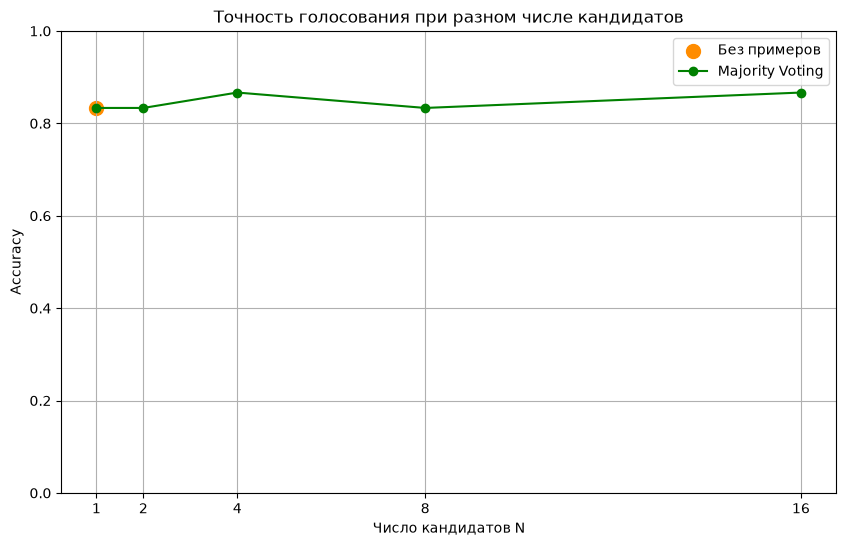

In [12]:
for level, accuracy in zip(majority_voting_levels, majority_voting_accuracies):
    print(f"Majority voting, n={level}: {accuracy:.3f}")

plt.figure(figsize=(10, 6))
plt.scatter([1], [sum(zero_shot_correctness) / len(zero_shot_correctness)], s=100, color="darkorange", marker="o", label='Без примеров')
plt.plot(majority_voting_levels, majority_voting_accuracies, marker='o', color="green", label='Majority Voting')
plt.xlabel('Число кандидатов N')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(majority_voting_levels)
plt.title('Точность голосования при разном числе кандидатов')
plt.legend()
plt.grid(True)
plt.show()

### 3. Выбор лучшего из N ответов с помощью генеративной модели вознаграждения (30 баллов)

Здесь мы реализуем второй метод увеличения вычислений на этапе формирования ответа — выбор лучшего из N вариантов с использованием генеративной модели вознаграждения. В частности:
- Для каждой задачи сгенерируйте несколько ответов (в данном случае — 16).
- Затем используйте большую языковую модель (LLM), чтобы сопоставить эти ответы и выбрать лучший. Это похоже на выбор лучшего из N вариантов с помощью модели вознаграждения, как в [этой статье](https://arxiv.org/abs/2408.03314), но вместо дискриминативной модели вознаграждения мы используем LLM в роли оценщика. Такой подход иногда называют [генеративной проверкой](https://arxiv.org/abs/2408.15240) или [генеративными моделями вознаграждения](https://arxiv.org/abs/2410.12832).
- Затем проверьте выбранный ответ, сравнив его с эталонным.
- **Дополнительное задание (2 балла):** мы предоставляем исходный промпт для генеративной модели вознаграждения. Если вы улучшите этот промпт и повысите точность метода относительно результатов со стандартным промптом, получите 2 дополнительных балла. Обязательного порога улучшения нет, но желательно добиться прироста примерно на 5 процентных пунктов.

Что нужно выполнить:
- Напишите код в области между метками `TODO: YOUR CODE STARTS HERE` и `TODO: YOUR CODE ENDS HERE`.
- Представьте ниже график.


Для каждой задачи получаем отдельный набор из 16 кандидатов. Оценщику передаём условие и полные решения без правильного ответа, затем сравниваем выбранный им ответ с эталоном. Точность сопоставляем с голосованием большинством при N=16.

Получено **26/30 верных ответов (86,67%)** — столько же, сколько при голосовании большинством с N=16. Для отбора выполнены 480 генераций кандидатов и 30 оценок. Все четыре незасчитанных ответа оценщика остались обещаниями вычисления или проверки без итогового числа.


In [13]:
class LLMVoting:
    """
    Класс использует LLM для объединения нескольких ответов и выбора лучшего.
    Для каждого запроса он генерирует несколько ответов и выбирает лучший отдельным вызовом LLM.
    """

    def __init__(
        self,
        model: str,
        system_prompt: str = None,
        n_samples: int = 16,
        temperature: float = 0.7,
        max_workers: int = 16
    ):
        """
        Инициализирует метод голосования с помощью LLM.

        Аргументы:
            model (str): Название используемой модели.
            system_prompt (str, необязательно): Системный запрос для модели.
            n_samples (int, необязательно): Число ответов на один запрос; по умолчанию 16.
            temperature (float, необязательно): Параметр исходного интерфейса; Cursor его не применяет.
        """
        self.sampler = SampleMultiple(
            model=model,
            system_prompt=system_prompt,
            n_samples=n_samples,
            temperature=temperature,
            max_workers=max_workers,
            stage="llm-candidates",
        )
        
        self.aggregator = SampleMultiple(
            model=model,
            system_prompt=system_prompt + """\n\nYou are a mathematical expert. You will be shown multiple solutions to a math problem.
Your task is to analyze these solutions and select the most likely correct answer.""",
            n_samples=1,
            temperature=0,  
            max_workers=max_workers,
            stage="llm-judge",
        )

    def _create_aggregation_prompts(self, problems: List[str], all_responses: List[List[str]]) -> List[str]:
        """
        Создаёт запросы для параллельного объединения ответов.
        
        Аргументы:
            problems (List[str]): Список исходных задач.
            all_responses (List[List[str]]): Списки ответов для каждой задачи.
            
        Возвращает:
            List[str]: Список запросов для модели-агрегатора.
        """
        return [
            f"""Here is a math problem:
{problem}

I have received multiple solutions. Here they are:

{chr(10).join(f'Solution {i+1}:{chr(10)}{r}' for i, r in enumerate(responses))}

Based on these solutions, restate the solution here that you think is most likely correct."""
            for problem, responses in zip(problems, all_responses)
        ]

    def __call__(self, prompts: Union[str, List[str]], all_responses=None) -> List[List[str]]:
        """
        Выполняет голосование с помощью LLM для заданных запросов.

        Аргументы:
            prompts (str или List[str]): Один запрос или список запросов.

        Возвращает:
            List[List[str]]: Выбранные ответы и все сгенерированные варианты.
        """
        # Получение нескольких вариантов ответа для каждого запроса
        if isinstance(prompts, str):
            prompts = [prompts]
        if all_responses is None:
            all_responses = self.sampler(prompts)
        if len(all_responses) != len(prompts) or any(len(r) != N_CANDIDATES for r in all_responses):
            raise ValueError("Для каждой задачи нужны ровно 16 кандидатов.")
        self.last_responses = all_responses
        aggregation_prompts = self._create_aggregation_prompts(prompts, all_responses)
        # Оценщик получает задачу и все варианты, но не эталонный ответ.
        return self.aggregator(aggregation_prompts)




llm-candidates:   0%|          | 0/480 [00:00<?, ?it/s]


llm-candidates: 100%|██████████| 480/480 [00:00<00:00, 120916.87it/s]


llm-judge:   0%|          | 0/30 [00:00<?, ?it/s]


llm-judge: 100%|██████████| 30/30 [00:00<00:00, 29888.15it/s]

LLM Voting Accuracy: 0.867
Correct: 26/30


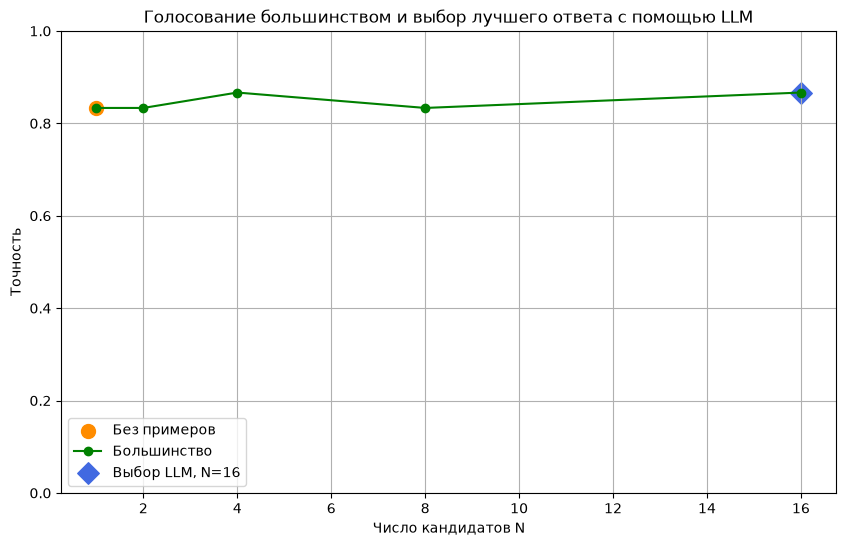

In [14]:
# Реализация и тестирование голосования с помощью LLM
llm_method = LLMVoting(
    model=MODEL_NAME,
    n_samples=N_CANDIDATES,
    temperature=0.7,
    system_prompt=system_prompt,
    max_workers=32
)

# Проверяем голосование LLM на тех же задачах
test_problems = problems
prompts = [problem["problem"] for problem in test_problems]

# Получаем предсказания метода голосования LLM
llm_predictions = llm_method(prompts)

# Вычисляем точность голосования LLM
correct_llm_voting = 0
total_llm_voting = len(test_problems)

for prediction, problem in zip(llm_predictions, test_problems):
    if verifier.verify(prediction[0], problem["answer"]):
        correct_llm_voting += 1

llm_voting_accuracy = correct_llm_voting / total_llm_voting
print(f"LLM Voting Accuracy: {llm_voting_accuracy:.3f}")
print(f"Correct: {correct_llm_voting}/{total_llm_voting}")

# Сопоставляем качество отбора по 16 кандидатам.
plt.figure(figsize=(10, 6))
plt.scatter([1], [zero_shot_accuracy], s=100, color="darkorange", label="Без примеров")
plt.plot(majority_voting_levels, majority_voting_accuracies, marker="o", color="green", label="Большинство")
plt.scatter([N_CANDIDATES], [llm_voting_accuracy], s=120, marker="D", color="royalblue", label="Выбор LLM, N=16")
plt.xlabel("Число кандидатов N")
plt.ylabel("Точность")
plt.title("Голосование большинством и выбор лучшего ответа с помощью LLM")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()




### 4. Итеративное самосовершенствование с использованием обратной связи от выполнения

В этом разделе реализуется система самосовершенствования, вдохновлённая подходом RLEF (обучение с подкреплением на основе обратной связи от выполнения), описанным в [работе Gehring и соавторов (2024)](https://arxiv.org/pdf/2410.02089). Система генерирует первоначальное решение, анализирует его недостатки, а затем создаёт улучшенное решение с учётом полученной обратной связи.

**Ключевая идея:** вместо генерации нескольких независимых вариантов мы создаём одно решение, после чего получаем адресную обратную связь и генерируем новый вариант. Это напоминает то, как люди учатся на ошибках и постепенно совершенствуют свои решения.

**Этапы процесса:**
1. **Первоначальная генерация:** создайте одно решение задачи.
2. **Этап критического анализа:** найдите ошибки в решении и сформулируйте конструктивную обратную связь.
3. **Повторная генерация:** создайте новое решение с учётом замечаний.
4. **Оценка:** сравните точность исходного и улучшенного решений.

**Требования:**
- Реализуйте систему критического анализа, использующую одну модель для генерации обратной связи.
- Реализуйте повторную генерацию решения на основе полученных замечаний.
- Проверьте систему на всех 30 задачах набора данных AIME25.
- Сравните точность до и после самосовершенствования.
- Проанализируйте эффективность подхода, основанного на обратной связи.


На всех 30 задачах выполняем цикл «исходное решение → критика → новое решение». Эталон доступен только проверщику. Измеряем точность до и после цикла, доли исправленных ответов и регрессий. Веса модели не обучаются. На каждом этапе используется Grok 4.7 внутри Cursor; инструменты отключены.

Выполнено 90 внешних запусков. Автоматическая точность исходных ответов — **24/30 (80,00%)**, после критики — **23/30 (76,67%)**. Проверщик не обнаружил исправлений; одна задача перешла из засчитанных в незасчитанные — **1/30 (3,33%)**.

Эта регрессия связана с разбором ответа: в задаче о делимости восьмизначных чисел исправленный текст правильно получает 279 и подробнее обосновывает подсчёт, но завершающее пояснение содержит число 2, которое извлекает проверщик. Поэтому падение автоматической метрики здесь не доказывает ухудшения математического решения.


In [15]:
class SelfImprovementSystem:
    """
    Выполняет цикл «решение → критика → новое решение» без обновления весов.
    Для генерации решений и критики используется Grok 4.7 через Cursor.
    """

    def __init__(self, model: str, system_prompt: str = None, temperature: float = 0.7, max_workers: int = 8):
        # Основной генератор первоначальных решений
        self.generator = SampleMultiple(
            model=model,
            system_prompt=system_prompt,
            n_samples=1,
            temperature=temperature,
            max_workers=max_workers,
            stage="self-initial",
        )
        
        # Модель-критик для формирования обратной связи
        critic_system_prompt = """You are an expert mathematical critic. Your job is to analyze mathematical solutions and provide constructive feedback.

When given a problem and its solution, analyze it for:
1. Logical errors and reasoning gaps
2. Mathematical mistakes and calculation errors
3. Conceptual misunderstandings
4. Missing steps or incomplete reasoning

Provide specific, actionable feedback that can help improve the solution. If the solution is correct, acknowledge that but still suggest potential improvements or alternative approaches.

Format your feedback as:
- **Issues Found:** [List specific problems]
- **Suggestions:** [How to fix the issues]
- **Overall Assessment:** [Brief summary]"""

        self.critic = SampleMultiple(
            model=model,
            system_prompt=critic_system_prompt,
            n_samples=1,
            temperature=0.3,  # Параметр исходного интерфейса; температура Cursor не управляется
            max_workers=max_workers,
            stage="self-critic",
        )
        
        # Генератор улучшенных решений с учётом обратной связи
        regenerator_system_prompt = """You are an expert mathematician who learns from feedback. When given a problem, your previous solution, and feedback about that solution, you should:

1. Carefully analyze the feedback provided
2. Identify the key issues that need to be addressed
3. Generate a new, improved solution that addresses the feedback
4. Ensure your new solution is logically sound and mathematically correct

Always acknowledge the feedback and explain how you've addressed the main issues in your new solution."""

        self.regenerator = SampleMultiple(
            model=model,
            system_prompt=regenerator_system_prompt,
            n_samples=1,
            temperature=temperature,
            max_workers=max_workers,
            stage="self-revised",
        )

    def _generate_initial_solution(self, problem: str) -> str:
        """Генерирует первоначальное решение задачи."""
        return self.generator(problem)[0][0]


    def _critique_solution(self, problem: str, solution: str) -> str:
        """
        Анализирует решение и формирует обратную связь.
        
        Аргументы:
            problem (str): Исходная задача.
            solution (str): Решение, которое нужно проверить.
            
        Возвращает:
            str: Замечания и рекомендации по решению.
        """
        prompt = (
            f"Problem:\n{problem}\n\nProposed solution:\n{solution}\n\n"
            "Analyze the solution and provide specific feedback on any mistakes."
        )
        return self.critic(prompt)[0][0]


    def _regenerate_solution(self, problem: str, original_solution: str, feedback: str) -> str:
        """
        Генерирует улучшенное решение на основе обратной связи.
        
        Аргументы:
            problem (str): Исходная задача.
            original_solution (str): Первоначальное решение.
            feedback (str): Замечания к первоначальному решению.
            
        Возвращает:
            str: Улучшенное решение.
        """
        prompt = (
            f"Problem:\n{problem}\n\nOriginal solution:\n{original_solution}\n\n"
            f"Feedback:\n{feedback}\n\n"
            "Write a complete improved solution, taking the feedback into account."
        )
        return self.regenerator(prompt)[0][0]


    def improve_solution(self, problem: str) -> dict:
        """
        Выполняет полный цикл самоулучшения RLEF для одной задачи.
        
        Аргументы:
            problem (str): Задача, которую необходимо решить.
            
        Возвращает:
            dict: Первоначальное решение, обратную связь и улучшенное решение.
        """
        original_solution = self._generate_initial_solution(problem)
        feedback = self._critique_solution(problem, original_solution)
        improved_solution = self._regenerate_solution(problem, original_solution, feedback)


        return {
            "problem": problem,
            "original_solution": original_solution,
            "feedback": feedback,
            "improved_solution": improved_solution
        }

    def evaluate_improvement(self, results: dict, correct_answer: str) -> dict:
        """
        Оценивает, стало ли улучшенное решение лучше первоначального.
        
        Аргументы:
            results (dict): Результаты метода improve_solution.
            correct_answer (str): Правильный ответ на задачу.
            
        Возвращает:
            dict: Результаты оценки, включая сравнение правильности ответов.
        """
        original_correct = bool(verifier.verify(results["original_solution"], correct_answer))
        improved_correct = bool(verifier.verify(results["improved_solution"], correct_answer))
        improvement = improved_correct and not original_correct

        return {
            "original_correct": original_correct,
            "improved_correct": improved_correct,
            "improvement": improvement, # логическое значение (bool)
            "correct_answer": correct_answer
        } 

In [16]:
# Инициализация системы самоулучшения (RLEF)
# Эта система использует только модель Grok 4.7 для генерации, критики и повторной генерации решений
self_improvement_system = SelfImprovementSystem(
    model=MODEL_NAME,
    temperature=0.7,
    system_prompt=system_prompt,
    max_workers=16
)

test_problems_size=len(problems)
test_problems = problems

print(f"Testing RLEF self-improvement system on {test_problems_size} problems...")
print("Для каждой задачи последовательно получаем решение, критику и исправленное решение.")
print(f"Using {MODEL_NAME} for generation, critique and regeneration.")
print()

# Сохраняем результаты для последующего анализа
improvement_results = []
original_accuracies = []
improved_accuracies = []

with ThreadPoolExecutor(max_workers=min(12, test_problems_size)) as executor:
    futures = [executor.submit(self_improvement_system.improve_solution, problem["problem"])
               for problem in test_problems]
    for i, (problem, future) in enumerate(zip(test_problems, futures)):
        print(f"Processing problem {i+1}/{test_problems_size}...")
        
        # Запускаем полный процесс самоулучшения RLEF
        result = future.result()
        
        # Оцениваем, удалось ли улучшить решение
        evaluation = self_improvement_system.evaluate_improvement(result, problem["answer"])
        
        # Сохраняем результаты
        improvement_results.append({
            "problem_index": i,
            "problem": problem["problem"],
            "correct_answer": problem["answer"],
            "result": result,
            "evaluation": evaluation
        })
        
        original_accuracies.append(evaluation["original_correct"])
        improved_accuracies.append(evaluation["improved_correct"])
        
        # Выводим ход выполнения
        if evaluation["improvement"]:
            print(f"  ✓ Improved from incorrect to correct!")
        elif evaluation["original_correct"] and evaluation["improved_correct"]:
            print(f"  → Both solutions correct")
        elif not evaluation["original_correct"] and not evaluation["improved_correct"]:
            print(f"  → Both solutions incorrect")
        else:
            print(f"  → Regressed from correct to incorrect")

print(f"\nCompleted processing {test_problems_size} problems!")

Testing RLEF self-improvement system on 30 problems...
Для каждой задачи последовательно получаем решение, критику и исправленное решение.
Using grok-4.7 for generation, critique and regeneration.




self-initial:   0%|          | 0/1 [00:00<?, ?it/s]


self-initial: 100%|██████████| 1/1 [00:00<00:00, 199.64it/s]


self-initial:   0%|          | 0/1 [00:00<?, ?it/s]


self-initial:   0%|          | 0/1 [00:00<?, ?it/s]

...


self-revised:   0%|          | 0/1 [00:00<?, ?it/s]


self-revised:   0%|          | 0/1 [00:00<?, ?it/s]


self-revised: 100%|██████████| 1/1 [00:00<00:00, 249.99it/s]



self-revised: 100%|██████████| 1/1 [00:00<00:00, 332.41it/s]

  → Both solutions correct
Processing problem 27/30...
  → Both solutions correct
Processing problem 28/30...
  → Both solutions correct
Processing problem 29/30...
  → Both solutions correct
Processing problem 30/30...
  → Both solutions correct

Completed processing 30 problems!


In [17]:
# Анализируем результаты
print("=== RLEF Self-Improvement Analysis ===")
print()

# Вычисляем общие показатели точности
original_accuracy = sum(original_accuracies) / len(original_accuracies)
improved_accuracy = sum(improved_accuracies) / len(improved_accuracies)
improvement_count = sum(1 for i in range(len(original_accuracies)) 
                       if improved_accuracies[i] and not original_accuracies[i])
regression_count = sum(1 for i in range(len(original_accuracies)) 
                     if original_accuracies[i] and not improved_accuracies[i])

print(f"Original Solution Accuracy: {original_accuracy:.3f} ({sum(original_accuracies)}/{len(original_accuracies)})")
print(f"Improved Solution Accuracy: {improved_accuracy:.3f} ({sum(improved_accuracies)}/{len(improved_accuracies)})")
print(f"Accuracy Improvement: {improved_accuracy - original_accuracy:.3f}")
print(f"Problems Improved: {improvement_count}")
print(f"Problems Regressed: {regression_count}")
print()

# Показываем подробные примеры успешных улучшений
print("=== Detailed Improvement Examples ===")
improvement_examples = [r for r in improvement_results if r["evaluation"]["improvement"]]

if improvement_examples:
    print(f"Found {len(improvement_examples)} successful improvements. Showing first example:")
    example = improvement_examples[0]
    
    print(f"\nProblem: {example['problem']}")
    print(f"Correct Answer: {example['correct_answer']}")
    print(f"\nOriginal Solution:")
    print(example['result']['original_solution'][:500] + "..." if len(example['result']['original_solution']) > 500 else example['result']['original_solution'])
    
    print(f"\nFeedback from {MODEL_NAME} Critic:")
    print(example['result']['feedback'][:500] + "..." if len(example['result']['feedback']) > 500 else example['result']['feedback'])
    
    print(f"\nImproved Solution:")
    print(example['result']['improved_solution'][:500] + "..." if len(example['result']['improved_solution']) > 500 else example['result']['improved_solution'])
else:
    print("No successful improvements found in this subset.")
print(f"Доля задач с исправленным ответом: {improvement_count / len(improvement_results):.1%}")
print(f"Доля задач с регрессией: {regression_count / len(improvement_results):.1%}")
print(f"Изменение относительно zero-shot: {improved_accuracy - zero_shot_accuracy:+.3f}")

# Сводные результаты дополняют сохранение каждого отдельного ответа.
request_records = response_store.records()
experiment_summary = {
    "protocol": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "model_parameters": MODEL_PARAMETERS,
    "problem_ids": [p["id"] for p in problems],
    "n_problems": len(problems),
    "n_candidates": N_CANDIDATES,
    "max_tokens": None,
    "backend": "cursor-sdk",
    "temperature_controlled": False,
    "budget_unit": "external_cursor_runs",
    "zero_shot": {"accuracy": zero_shot_accuracy, "correctness": zero_shot_correctness,
                  "predictions": zero_shot_predictions},
    "majority": {"levels": majority_voting_levels, "accuracies": majority_voting_accuracies,
                 "predictions": all_responses_list, "candidates": majority_candidates},
    "llm_voting": {"accuracy": llm_voting_accuracy, "predictions": llm_predictions,
                   "candidates": llm_method.last_responses},
    "self_improvement": {"original_accuracy": original_accuracy, "improved_accuracy": improved_accuracy,
                         "improved_count": improvement_count, "regressed_count": regression_count,
                         "results": improvement_results},
    "completed_requests": len(request_records),
    "answers_stopped_at_token_limit": None,
}
ResponseStore.write_json(CHECKPOINT_DIR / "results.json", experiment_summary)
print(f"Завершённых внешних запусков Cursor: {len(request_records)}.")

print("Число внутренних вызовов модели и причины завершения по токенам не предоставлены.")


=== RLEF Self-Improvement Analysis ===

Original Solution Accuracy: 0.800 (24/30)
Improved Solution Accuracy: 0.767 (23/30)
Accuracy Improvement: -0.033
Problems Improved: 0
Problems Regressed: 1

=== Detailed Improvement Examples ===
No successful improvements found in this subset.
Доля задач с исправленным ответом: 0.0%
Доля задач с регрессией: 3.3%
Изменение относительно zero-shot: -0.067


Завершённых внешних запусков Cursor: 1110.
Число внутренних вызовов модели и причины завершения по токенам не предоставлены.


## Анализ и обсуждение результатов (15 баллов)

### Что необходимо представить

**Обязательно:** выполните следующие аналитические задания, опираясь на результаты экспериментов из предыдущих разделов.

### Задание 1. График сравнения эффективности методов (5 баллов)

Постройте общий сравнительный график, включающий:
1. Базовый результат без примеров (одна точка).
2. Точность голосования большинством при числе ответов [1, 2, 4, 8, 16].
3. Точность голосования с использованием LLM (одна точка для 16 ответов).
4. Точность метода самосовершенствования (одна точка, отражающая улучшение).

Требования:
- Используйте значения точности, вычисленные в предыдущих разделах.
- Добавьте понятные подписи, легенду и заголовок.
- Используйте разные цвета и маркеры для каждого метода.
- Установите подходящие границы осей и добавьте сетку.
- Примечание: метод самосовершенствования использует 3 обращения к API для каждой задачи (первоначальная генерация + критический анализ + повторная генерация).


Сопоставляем точность четырёх методов на одних и тех же 30 задачах. Для голосования показываем все пять значений N; для самосовершенствования — результат после критики. Затем рассчитываем разницы точности и разбираем примеры исправлений и ошибок. Затраты сравниваем по числу внешних запусков агента, поскольку число внутренних вызовов модели неизвестно.

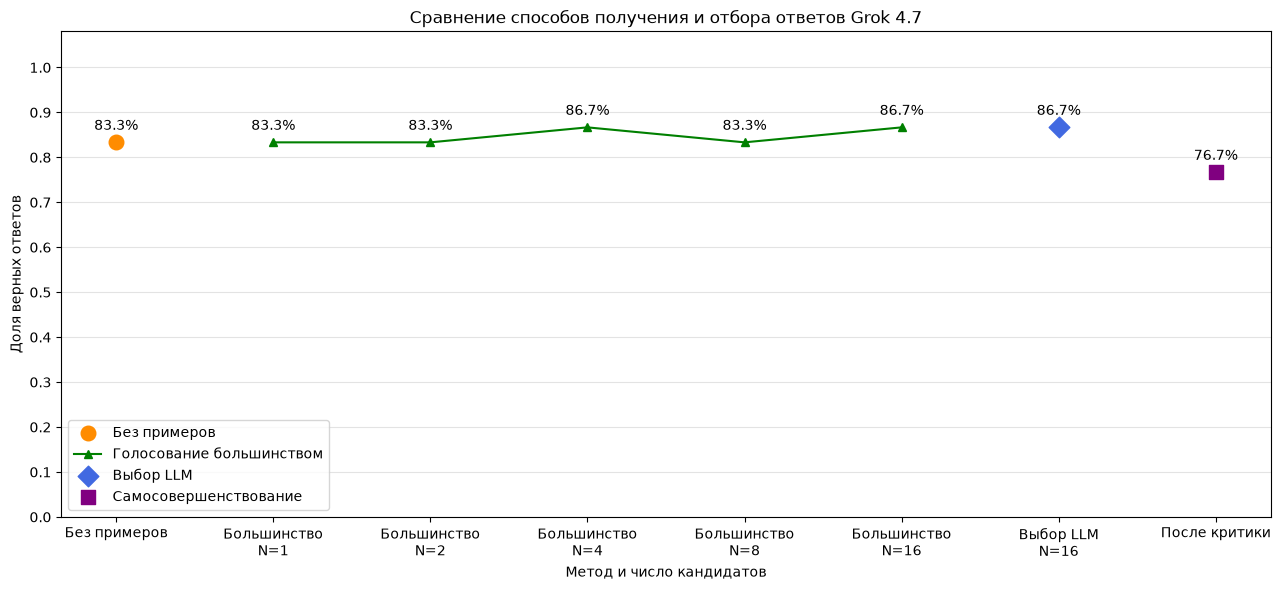

Ранжирование по точности:
Большинство N=4: 86.7% (26/30)
Большинство N=16: 86.7% (26/30)
Выбор LLM N=16: 86.7% (26/30)
Без примеров: 83.3% (25/30)
Большинство N=1: 83.3% (25/30)
Большинство N=2: 83.3% (25/30)
Большинство N=8: 83.3% (25/30)
После критики: 76.7% (23/30)

Изменение точности при увеличении N:
1 → 2: +0.00 п.п.
2 → 4: +3.33 п.п.
4 → 8: -3.33 п.п.
8 → 16: +3.33 п.п.
После критики относительно исходного решения: -3.33 п.п.
После критики относительно zero-shot: -6.67 п.п.
Исправлены ответы: 0/30; регрессии: 1/30.


In [18]:
# Общее сравнение по фактически рассчитанным точностям.
comparison_labels = ["Без примеров"] + [
    f"Большинство\nN={n}" for n in majority_voting_levels
] + ["Выбор LLM\nN=16", "После критики"]
comparison_scores = (
    [zero_shot_accuracy] + majority_voting_accuracies
    + [llm_voting_accuracy, improved_accuracy]
)
majority_positions = list(range(1, len(majority_voting_levels) + 1))
llm_position = len(majority_voting_levels) + 1
improvement_position = llm_position + 1

plt.figure(figsize=(13, 6))
plt.scatter([0], [zero_shot_accuracy], color="darkorange", marker="o", s=110, label="Без примеров")
plt.plot(
    majority_positions, majority_voting_accuracies,
    color="green", marker="^", label="Голосование большинством",
)
plt.scatter([llm_position], [llm_voting_accuracy], color="royalblue", marker="D", s=110, label="Выбор LLM")
plt.scatter([improvement_position], [improved_accuracy], color="purple", marker="s", s=110, label="Самосовершенствование")
for position, score in enumerate(comparison_scores):
    plt.annotate(f"{score:.1%}", (position, score), xytext=(0, 9), textcoords="offset points", ha="center")
plt.xticks(range(len(comparison_labels)), comparison_labels)
plt.xlabel("Метод и число кандидатов")
plt.ylabel("Доля верных ответов")
plt.title("Сравнение способов получения и отбора ответов Grok 4.7")
plt.ylim(0, 1.08)
plt.yticks([i / 10 for i in range(11)])
plt.grid(axis="y", alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

ranked_methods = sorted(
    zip(comparison_labels, comparison_scores), key=lambda item: item[1], reverse=True,
)
print("Ранжирование по точности:")
for label, score in ranked_methods:
    print(f"{label.replace(chr(10), ' ')}: {score:.1%} ({round(score * len(problems))}/{len(problems)})")
print("\nИзменение точности при увеличении N:")
for i in range(1, len(majority_voting_levels)):
    previous_n, current_n = majority_voting_levels[i - 1:i + 1]
    delta = majority_voting_accuracies[i] - majority_voting_accuracies[i - 1]
    print(f"{previous_n} → {current_n}: {delta * 100:+.2f} п.п.")
print(f"После критики относительно исходного решения: {(improved_accuracy - original_accuracy) * 100:+.2f} п.п.")
print(f"После критики относительно zero-shot: {(improved_accuracy - zero_shot_accuracy) * 100:+.2f} п.п.")
print(f"Исправлены ответы: {improvement_count}/{len(problems)}; регрессии: {regression_count}/{len(problems)}.")


## **Задание 2. Количественный анализ (5 баллов)**


На основе результатов экспериментов ответьте на следующие вопросы, подкрепив ответы конкретными числовыми данными:

1. **Ранжирование по точности:** расположите методы в порядке убывания точности. Приведите фактические значения точности для каждого метода.



2. **Эффективность вычислительных затрат:** рассчитайте прирост точности на каждый дополнительный вызов API для голосования большинством (при увеличении числа ответов с n=1 до n=16) и сравните его с самосовершенствованием (всего 3 вызова API). Какой метод обеспечивает большую отдачу от дополнительных вычислений?



3. **Анализ самосовершенствования:**
   - Насколько повышается точность благодаря самосовершенствованию по сравнению с ответами без примеров?
   - Судя по анализу категорий ошибок, какие ошибки чаще всего встречаются в неправильных решениях: логические, математические, концептуальные или связанные с неполнотой ответа?
   - Для какого процента задач удалось улучшить решение?



## **Задание 3. Выводы по отдельным методам (5 баллов)**


Ответьте на следующие вопросы о реализованных методах:

1. **Голосование большинством:**
   - При каком количестве сгенерированных ответов дальнейшее увеличение их числа начинает давать всё меньший эффект? Укажите момент, когда прирост точности становится минимальным.
   - Какова максимальная точность, достигнутая методом голосования большинством?


2. **Голосование с использованием LLM:**
   - Как точность голосования с использованием LLM соотносится с голосованием большинством при n=16?
   - Чем отличаются вычислительные затраты этих методов при n=16?




3. **Самосовершенствование:**
   - Как метод самосовершенствования соотносится с традиционными методами увеличения вычислений на этапе формирования ответа?
   - Каковы преимущества и недостатки повторной генерации с учётом обратной связи по сравнению с генерацией нескольких независимых решений?
   - Какие категории ошибок, по результатам ваших экспериментов, наиболее важны для эффективного улучшения решений?






**Количественный анализ**

**1. Ранжирование по точности.** Сравнение по штатному проверщику на 30 задачах:

| Метод | Верные ответы | Точность |
|---|---:|---:|
| Большинство, N=4 | 26/30 | 86,67% |
| Большинство, N=16 | 26/30 | 86,67% |
| Выбор LLM, N=16 | 26/30 | 86,67% |
| Без примеров | 25/30 | 83,33% |
| Большинство, N=1 | 25/30 | 83,33% |
| Большинство, N=2 | 25/30 | 83,33% |
| Большинство, N=8 | 25/30 | 83,33% |
| После критики | 23/30 | 76,67% |

Это результаты одного прогона: одна задача меняет точность на 3,33 п.п. Часть различий зависит от разбора текста. Например, базовый ответ на задачу с пятиугольником лишь упоминает угол 60°, но получает положительную оценку, поскольку 60 совпадает с эталоном. При N=4 два голоса за 60 также происходят из незавершённых текстов. Поэтому автоматическая точность не подтверждает полноту всех засчитанных решений.

**2. Отдача дополнительных вычислений.** Для Cursor считаем внешние успешные запуски агента; число внутренних вызовов модели и денежная стоимость неизвестны. При переходе от N=1 к N=16 большинство получает ещё 15 запусков на задачу:

$$
\frac{26/30-25/30}{16-1}=\frac1{450},
$$

или **0,22 п.п. на дополнительный запуск на задачу**. Для самосовершенствования сравниваем его собственное первоначальное решение с результатом после двух дополнительных этапов:

$$
\frac{23/30-24/30}{3-1}=-\frac1{60},
$$

или **−1,67 п.п. на дополнительный запуск на задачу**. На всём наборе это 450 дополнительных запусков для большинства и 60 для критики с повторной генерацией. По автоматической метрике отдача выше у большинства. При этом единственная регрессия самосовершенствования вызвана ошибкой извлечения ответа, а не потерей правильного математического результата. Эти числа не измеряют реальную стоимость или качество рассуждений.

**3. Что получилось при самосовершенствовании.** Точность после критики — **23/30 (76,67%)**, что на **6,67 п.п. ниже** базовых 25/30. Внутри самого цикла она изменилась с **24/30 (80,00%) до 23/30**, то есть на **−3,33 п.п.** Базовые ответы и первоначальные ответы цикла получены отдельно, поэтому влияние критики оцениваем по второй, парной разнице.

Переходов «неверно → верно» — **0/30 (0%)**; «верно → неверно» по проверщику — **1/30 (3,33%)**. Остались верными 23 ответа, не прошли проверку на обоих этапах шесть.

Ручной разбор шести первоначальных незасчитанных ответов показал:

- В задачах о дугах девятиточечной окружности, кубах по модулю \(3^7\), минимумах рациональной функции и рекуррентной последовательности ответ остаётся планом вычисления. Итоговое число не получено.
- В задаче о раскраске сетки \(2\times2\) текст несколько раз получает 82, но заканчивается обещанием проверить все \(2^{12}\) раскрасок. Проверщик извлекает 12. Критика и повторный ответ также остаются обещаниями проверки.
- В задаче с пятиугольником дан явный неверный итог 36 и необоснованный подбор формулы. Есть проверяемая арифметическая ошибка: \(26+7\sqrt3\approx38{,}124\), тогда как модель пишет \(48{,}124\). Повторный ответ обещает пересчёт, но результата не даёт.

Таким образом, у **пяти из шести** основной причиной незачёта служит неполнота или отсутствие надёжно выделенного итога. В шестом наблюдаются математическая ошибка и необоснованный вывод. Это разбор конкретных текстов, а не автоматическая классификация по замечаниям критика.

Отдельно разобрана единственная регрессия. В задаче о делимости восьмизначных чисел на 22 исходный ответ равен 279. Критик обоснованно просит уточнить переход по модулю 11 и исключить наборы из нуля или четырёх нечётных цифр. Повторный текст исправляет эти пробелы и снова получает 279. Однако после ответа идёт пояснение учёта замечаний, заканчивающееся обсуждением множителя 2; проверщик выбирает 2. Здесь снизилась автоматическая оценка, хотя математическое обоснование стало подробнее.

**Выводы по отдельным методам**

**1. Голосование большинством.** Последовательные изменения при увеличении N равны **0; +3,33; −3,33; +3,33 п.п.** Максимум — **26/30 (86,67%)**, достигнутый при **N=4 и N=16**. После N=4 дальнейшее увеличение не даёт итогового выигрыша, а при N=8 точность даже снижается. Минимальный неотрицательный прирост наблюдается на переходе 1→2 и равен нулю: при двух различных ответах правило равенства голосов сохраняет первый. На переходе 4→8 изменение отрицательное. Устойчивая монотонная точка насыщения этим прогоном не установлена.

**2. Выбор с помощью LLM.** Получено **26/30 (86,67%)** против **26/30 (86,67%)** у большинства при N=16; разница составляет **0,00 п.п.** Пулы кандидатов раздельны, поэтому разницу нельзя приписать исключительно способу отбора.

На задачу большинство требует 16 внешних запусков, LLM-отбор — 16 для кандидатов и ещё один для оценщика. На 30 задачах это **480 против 510**, то есть **на 30 запусков, или 6,25%, больше**. Вход оценщика содержит все 16 решений, поэтому разница в числе запусков не равна разнице в стоимости или времени. Во всех четырёх незасчитанных ответах — в задачах о рассадке, кубах, пересечении кривых и пятиугольнике — оценщик лишь обещает проверку или вычисление вместо итогового числа. В этом прогоне дополнительный запуск оценщика не повысил точность относительно большинства при N=16.

**3. Самосовершенствование и увеличение вычислений.** Большинство использует несколько вариантов и частоту их ответов; LLM-отбор дополнительно анализирует варианты. Самосовершенствование тратит три последовательных запуска на одну цепочку «решение → критика → новое решение». Оно может уточнять уже найденный ход и исправлять пробелы в доказательстве, что видно на примере ответа 279. Обновления весов здесь нет: это использование обратной связи при формировании ответа, а не обучение модели.

Недостатки проявились в незавершённых планах, неконкретной критике и отсутствии итогового вычисления после замечаний. Длиннее написанное решение не обязательно становится завершённым: так произошло с задачей о дугах. Несколько отдельных сессий дают больше вариантов, но не гарантируют статистической независимости; критика тоже не гарантирует правильности.

В этом прогоне прежде всего важны **завершение решения и однозначный итоговый ответ**. Далее необходимы проверка арифметики и обоснование выбранной геометрической формулы, а также полнота перебора и корректность модульных переходов. Уточнение доказательства и исправление итогового числа — разные изменения: первое наблюдалось, переходов к правильному числу по автоматической оценке не было.

**Совпадение ошибок между методами**

Номера обозначают позиции задач в общей выборке из 30 задач, начиная с 1. В таблице приведены результаты штатного проверщика.

| Метод | Не прошедшие проверку задачи |
|---|---|
| Zero-shot | 1, 2, 5, 13, 16 |
| Большинство N=1/2/8 | 1, 2, 13, 16, 18 |
| Большинство N=4/16 | 1, 2, 13, 16 |
| LLM-отбор | 2, 18, 24, 26 |
| Самосовершенствование, до | 1, 2, 13, 16, 18, 21 |
| Самосовершенствование, после | 1, 2, 13, 16, 18, 21, 23 |

Только задача №2 не прошла проверку у всех методов. У большинства при N=16 и LLM-отбора одинаковая точность 26/30, но совпадает лишь одна ошибка из четырёх. Пулы кандидатов раздельны, поэтому различие нельзя объяснять только способом отбора. Ошибка №23 после самосовершенствования связана с извлечением числа из правильного решения.

### Задача №1

Номер соответствует позиции в общей выборке из 30 задач.

Suppose $\triangle ABC$ has angles $\angle BAC = 84^\circ, \angle ABC=60^\circ,$ and $\angle ACB = 36^\circ.$ Let $D, E,$ and $F$ be the midpoints of sides $\overline{BC}, \overline{AC},$ and $\overline{AB},$ respectively. The circumcircle of $\triangle DEF$ intersects $\overline{BD}, \overline{AE},$ and $\overline{AF}$ at points $G, H,$ and $J,$ respectively. The points $G, D, E, H, J,$ and $F$ divide the circumcircle of $\triangle DEF$ into six minor arcs, as shown. Find $\widehat{DE}+2\cdot \widehat{HJ} + 3\cdot \widehat{FG},$ where the arcs are measured in degrees.

Код рисунка (Asymptote):

```asy
import olympiad; size(6cm); defaultpen(fontsize(10pt)); pair B = (0, 0), A = (Cos(60), Sin(60)), C = (Cos(60)+Sin(60)/Tan(36), 0), D = midpoint(B--C), E = midpoint(A--C), F = midpoint(A--B); guide circ = circumcircle(D, E, F); pair G = intersectionpoint(B--D, circ), J = intersectionpoints(A--F, circ)[0], H = intersectionpoints(A--E, circ)[0]; draw(B--A--C--cycle); draw(D--E--F--cycle); draw(circ);  dot(A);dot(B);dot(C);dot(D);dot(E);dot(F);dot(G);dot(H);dot(J); label("$A$", A, (0, .8)); label("$B$", B, (-.8, -.8)); label("$C$", C, (.8, -.8)); label("$D$", D, (0, -.8)); label("$E$", E, (.8, .2)); label("$F$", F, (-.8, .2)); label("$G$", G, (0, .8)); label("$H$", H, (-.2, -1));label("$J$", J, (.2, -.8));
```

**Правильный ответ:** $336$.

**Ответы методов**

В таблице показаны извлечённые значения и условные подстановки в квадратных скобках; их смысл пояснён в конце работы. Зелёным отмечены совпадения с эталоном. Извлечённое число может быть промежуточным: само по себе оно не означает, что модель завершила решение.

| Метод | Значение |
|---|---|
| Zero-shot | 180 |
| Большинство N=1 | 0 |
| Большинство N=2 | 0 |
| Большинство N=4 | 180 |
| Большинство N=8 | 180 |
| Большинство N=16 | 180 |
| LLM-отбор | <span style="color: #008000"><b>336 ✓</b></span> |
| Самосовершенствование, до | 180 |
| Самосовершенствование, после | 2 |


### Задача №2

Номер соответствует позиции в общей выборке из 30 задач.

Let $N$ denote the number of ordered triples of positive integers $(a, b, c)$ such that $a, b, c \leq 3^6$ and $a^3 + b^3 + c^3$ is a multiple of $3^7$. Find the remainder when $N$ is divided by $1000$.

**Правильный ответ:** $735$.

**Ответы методов**

В таблице показаны значения, извлечённые штатным проверщиком из сохранённых ответов. Зелёным отмечены совпадения с эталоном. Извлечённое число может быть промежуточным: само по себе оно не означает, что модель завершила решение.

| Метод | Значение, извлечённое проверщиком |
|---|---|
| Zero-shot | 1000 |
| Большинство N=1 | 1 |
| Большинство N=2 | 1 |
| Большинство N=4 | 1 |
| Большинство N=8 | 6 |
| Большинство N=16 | 6 |
| LLM-отбор | 3 |
| Самосовершенствование, до | 6 |
| Самосовершенствование, после | 3 |


### Задача №16

Номер соответствует позиции в общей выборке из 30 задач.

Let the sequence of rationals $x_1,x_2,\dots$ be defined such that $x_1=\frac{25}{11}$ and\[x_{k+1}=\frac{1}{3}\left(x_k+\frac{1}{x_k}-1\right).\]$x_{2025}$ can be expressed as $\frac{m}{n}$ for relatively prime positive integers $m$ and $n$. Find the remainder when $m+n$ is divided by $1000$.

**Правильный ответ:** $248$.

**Ответы методов**

В таблице показаны извлечённые значения и условные подстановки в квадратных скобках; их смысл пояснён в конце работы. Зелёным отмечены совпадения с эталоном. Извлечённое число может быть промежуточным: само по себе оно не означает, что модель завершила решение.

| Метод | Значение |
|---|---|
| Zero-shot | 1 |
| Большинство N=1 | 1 |
| Большинство N=2 | 1 |
| Большинство N=4 | 1 |
| Большинство N=8 | 1 |
| Большинство N=16 | 1 |
| LLM-отбор | <span style="color: #008000"><b>248 ✓</b></span> |
| Самосовершенствование, до | 1 |
| Самосовершенствование, после | 2025 |


### Задача №24

Номер соответствует позиции в общей выборке из 30 задач.

Sixteen chairs are arranged in a row. Eight people each select a chair in which to sit so that no person sits next to two other people. Let $N$ be the number of subsets of $16$ chairs that could be selected. Find the remainder when $N$ is divided by $1000$.

**Правильный ответ:** $907$.

**Ответы методов**

В таблице показаны извлечённые значения и условные подстановки в квадратных скобках; их смысл пояснён в конце работы. Зелёным отмечены совпадения с эталоном. Извлечённое число может быть промежуточным: само по себе оно не означает, что модель завершила решение.

| Метод | Значение |
|---|---|
| Zero-shot | <span style="color: #008000"><b>907 ✓</b></span> |
| Большинство N=1 | <span style="color: #008000"><b>907 ✓</b></span> |
| Большинство N=2 | <span style="color: #008000"><b>907 ✓</b></span> |
| Большинство N=4 | <span style="color: #008000"><b>907 ✓</b></span> |
| Большинство N=8 | <span style="color: #008000"><b>907 ✓</b></span> |
| Большинство N=16 | <span style="color: #008000"><b>907 ✓</b></span> |
| LLM-отбор | 8 |
| Самосовершенствование, до | <span style="color: #008000"><b>907 ✓</b></span> |
| Самосовершенствование, после | <span style="color: #008000"><b>907 ✓</b></span> |
